# 5% 600K PEG — Per-cell $K$, $n$ (live techniques, no multi-cell bank)

**Platform goal.** Characterize **each cell independently** for non-Newtonian $(K,n)$.  
Methods that need an average $n$ or calibration bank from other samples are **out of scope** and removed.

**One-sentence takeaway.** On this PEG, **$n$ is already near the 10% band per cell**; **$K$ is limited by hit/gap geometry**. If hit is held to **$\pm 0.01\,\mathrm{mm}$**, the manual height curve says geometric error is only ~**4% on $K$** and ~**1% on $n$** — so 10% is achievable **per cell** once live gap handling matches that floor. Today's larger $K$ bias is not fixed by multi-cell averaging.

## How to read
1. Raw drag (manual + each auto cell)
2. Manual GT + **geometric floor at $\pm 0.01\,\mathrm{mm}$**
3. Production per-cell bars
4. **Live, single-cell** candidate methods (bars + errors)
5. What to implement next in the controller

**Data:** manual `5%600KPEG_MANUAL_RAW.csv` (13 μm/inc); auto `5%600K_PEG_reproducibility_20261119.csv` (6 cells).


## 1. Setup & load


In [1]:
from __future__ import annotations
import sys
from pathlib import Path
from typing import Any, Dict, List, Tuple
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit

NOTEBOOK_DIR = Path.cwd().resolve()
ROOT = None
for candidate in [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]:
    if (candidate / "src" / "viscometry").is_dir():
        ROOT = candidate
        break
if ROOT is None:
    ROOT = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(ROOT / "src"))

from viscometry.rheology.constants import PCT_TO_PA, shear_rate, H_C_UNIVERSAL_MM
from viscometry.rheology.live_adapter import filter_measurement_points, predict_cell_rheology
from viscometry.rheology.prediction import fit_drag, fit_powerlaw
from viscometry.rheology.stress_powerlaw import fit_stress_powerlaw

MANUAL_CSV = ROOT / "results/auto_runs/5%600KPEG_MANUAL_RAW.csv"
AUTO_CSV = ROOT / "results/auto_runs/5%600K_PEG_reproducibility_20261119.csv"
G_REF = 20.0
MANUAL_INC_MM = 0.013
# CSV increment whose torque series matches the physically identified hit (prior drag analysis).
# In an earlier paste this series was labeled 0; in the current CSV it is Increment 1 (5616 cP @ 5 rpm).
HIT_INC = 1
HIT_FLOOR_MM = 0.01   # target geometric hit accuracy
HIT_BUDGET_MM = 0.20  # today's practical uncertainty (for comparison)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print(f"ROOT={ROOT}")
print(f"Manual step={MANUAL_INC_MM*1e3:.0f} um | HIT_INC={HIT_INC} | geometric floor +/-{HIT_FLOOR_MM*1e3:.0f} um")
assert MANUAL_CSV.exists() and AUTO_CSV.exists()


ROOT=/Users/ianng/Documents/GitHub/Automated_Viscometry
Manual step=13 um | HIT_INC=1 | geometric floor +/-10 um


In [2]:
def load_manual(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Formulation"] = df["Formulation"].ffill()
    for col in ["Increment", "speed_RPM", "SR_1/s", "Viscosity_cP", "Torque_%", "SS_dyne/cm2", "Accuracy_cP"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    missing = df["SS_dyne/cm2"].isna()
    df.loc[missing, "SS_dyne/cm2"] = df.loc[missing, "Viscosity_cP"] * df.loc[missing, "SR_1/s"] / 100.0
    df["tau_Pa"] = df["SS_dyne/cm2"] / 10.0
    df["gamma_dot_1_s"] = df["SR_1/s"]
    df["drag"] = df["Torque_%"] / df["speed_RPM"]
    df["h_rel_mm"] = (df["Increment"] - HIT_INC) * MANUAL_INC_MM
    return df


def load_auto_experiments(path: Path) -> List[Dict[str, Any]]:
    raw = path.read_text().splitlines()
    chunks, cur_ts, header, buf = [], None, None, []

    def flush():
        nonlocal buf
        if buf and header is not None:
            d = pd.DataFrame(buf, columns=header)
            d["timestamp"] = cur_ts
            chunks.append(d)
        buf = []

    for line in raw:
        if line.startswith("# Timestamp:"):
            flush(); cur_ts = line.split("Timestamp:")[1].strip().rstrip(","); continue
        if line.startswith("cell,"):
            flush(); header = line.split(","); continue
        parts = line.split(",")
        if header is None or len(parts) != len(header):
            continue
        try:
            float(parts[1]); float(parts[2]); float(parts[4])
        except ValueError:
            continue
        if parts[0] in ("", "nan"):
            continue
        buf.append(parts)
    flush()
    auto = pd.concat(chunks, ignore_index=True)
    for col in ["cell", "Z_Height_mm", "RPM", "Elapsed_Time_s", "Torque_%", "Rotational_Drag"]:
        auto[col] = pd.to_numeric(auto[col], errors="coerce")
    auto = auto.dropna(subset=["cell", "Z_Height_mm", "RPM", "Torque_%"])
    auto["cell"] = auto["cell"].astype(int)
    exps = []
    for (ts, cell), g in auto.groupby(["timestamp", "cell"]):
        g_ord = g.reset_index(drop=True)
        zz = g_ord["Z_Height_mm"].to_numpy()
        breaks = [0]
        for i in range(1, len(zz)):
            if zz[i] - zz[i - 1] > 0.05:
                breaks.append(i)
        breaks.append(len(zz))
        multi = len(breaks) > 2
        for j, (a, b) in enumerate(zip(breaks[:-1], breaks[1:])):
            sub = g_ord.iloc[a:b].copy()
            name = f"{ts}_cell{cell}" + (f"_seg{j}" if multi else "")
            short = f"c{cell}" + (f"s{j}" if multi else "")
            if str(ts).startswith("20261125"):
                short = f"c{cell}_d2"
            exps.append({"name": name, "short": short, "timestamp": ts, "cell": int(cell), "df": sub})
    return exps


def hit_z_from_flags(df: pd.DataFrame) -> float:
    conf = df[df["Confirm_hit"].astype(str).str.upper().eq("HIT")]
    if len(conf):
        return float(conf["Z_Height_mm"].max())
    hits = df[df["Hit_Detected"].astype(str).str.upper().eq("TRUE")]
    if len(hits):
        return float(hits["Z_Height_mm"].max())
    return float(df["Z_Height_mm"].min())


manual = load_manual(MANUAL_CSV)
exps = load_auto_experiments(AUTO_CSV)
print(f"Manual rows={len(manual)} incs={manual['Increment'].nunique()} HIT_INC={HIT_INC}")
print(f"Auto experiments={len(exps)}")
for e in exps:
    d = e["df"]; zs = np.sort(d["Z_Height_mm"].unique())
    print(f"  {e['short']:8s} Z {zs.max():.2f}->{zs.min():.2f} span={zs.max()-zs.min():.3f} mm")


Manual rows=130 incs=26 HIT_INC=1
Auto experiments=6
  c1       Z -65.60->-65.96 span=0.360 mm
  c2       Z -65.40->-65.80 span=0.400 mm
  c3       Z -65.30->-65.66 span=0.360 mm
  c7       Z -65.54->-65.94 span=0.400 mm
  c8       Z -65.38->-65.62 span=0.240 mm
  c7_d2    Z -65.54->-65.94 span=0.400 mm


## 2. Raw rotational drag

Same $D=T/\mathrm{RPM}$ signal on both platforms. Green band = **$\pm 0.01\,\mathrm{mm}$** target geometric floor; light red = today's ~$\pm 0.20\,\mathrm{mm}$ budget.


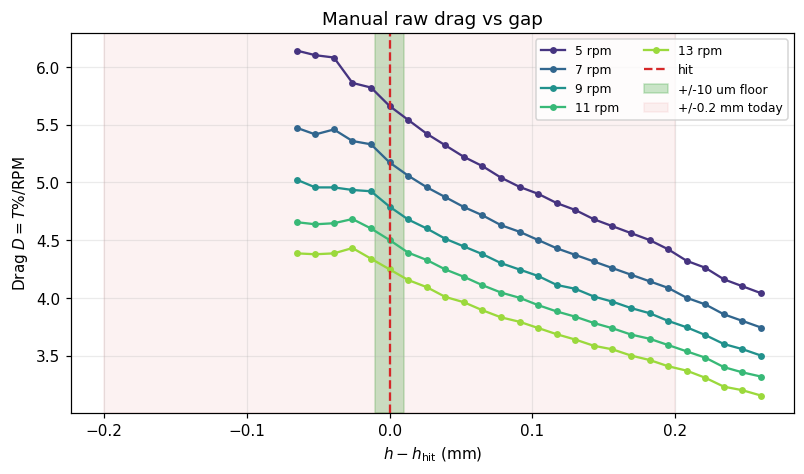

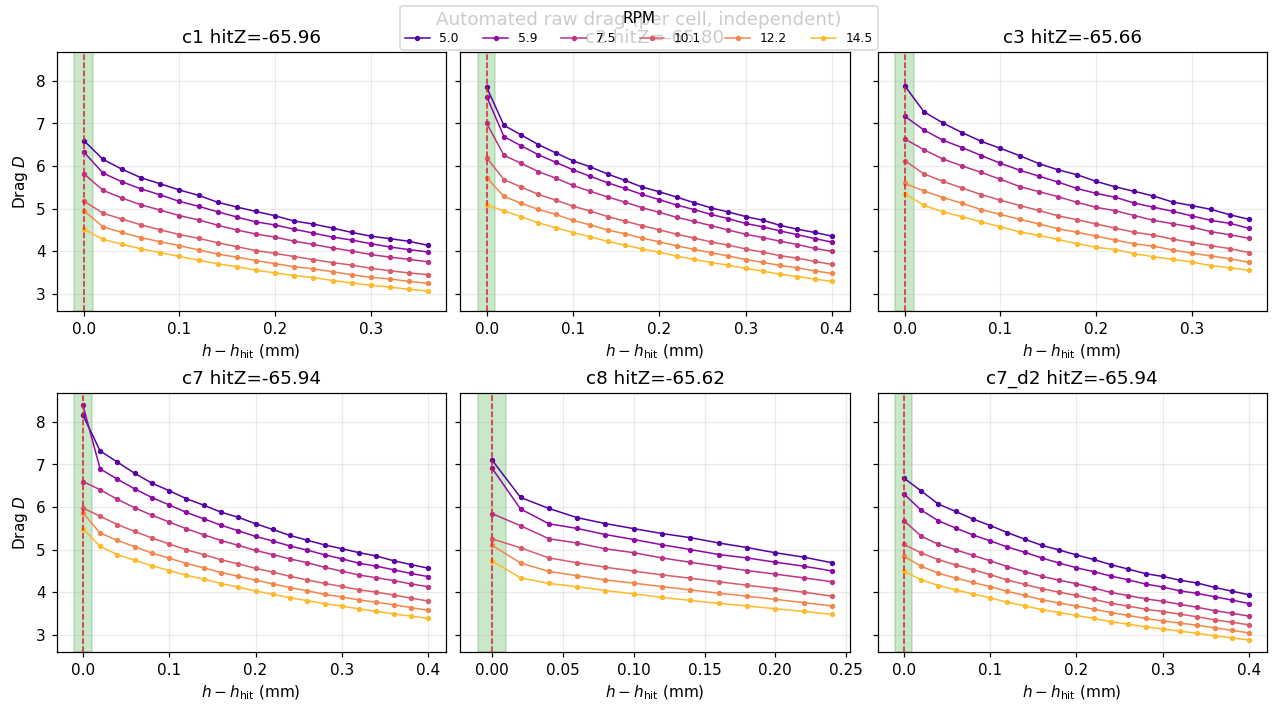

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
rpms_m = sorted(manual["speed_RPM"].unique())
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(rpms_m)))
for rpm, color in zip(rpms_m, cmap):
    sub = manual[manual["speed_RPM"] == rpm].sort_values("h_rel_mm")
    ax.plot(sub["h_rel_mm"], sub["drag"], "o-", ms=3.5, color=color, label=f"{int(rpm)} rpm")
ax.axvline(0.0, color="C3", ls="--", label="hit")
ax.axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.25, label=f"+/-{HIT_FLOOR_MM*1e3:.0f} um floor")
ax.axvspan(-HIT_BUDGET_MM, HIT_BUDGET_MM, color="C3", alpha=0.06, label=f"+/-{HIT_BUDGET_MM} mm today")
ax.set_xlabel(r"$h-h_{\mathrm{hit}}$ (mm)")
ax.set_ylabel(r"Drag $D=T\%/\mathrm{RPM}$")
ax.set_title("Manual raw drag vs gap")
ax.legend(ncols=2, fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.2), constrained_layout=True, sharey=True)
axes = axes.ravel()
for ax, exp in zip(axes, exps):
    d = exp["df"].copy()
    hz = hit_z_from_flags(d)
    d["h_rel_mm"] = d["Z_Height_mm"] - hz
    rpms = sorted(d["RPM"].unique())
    colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(rpms)))
    for rpm, color in zip(rpms, colors):
        sub = d[np.isclose(d["RPM"], rpm)].sort_values("h_rel_mm")
        drag = sub["Rotational_Drag"]
        if drag.isna().all():
            drag = sub["Torque_%"] / sub["RPM"]
        ax.plot(sub["h_rel_mm"], drag, "o-", ms=2.5, color=color, lw=1.0, label=f"{rpm:.1f}")
    ax.axvline(0.0, color="C3", ls="--", lw=1.0)
    ax.axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.25)
    ax.set_title(f"{exp['short']} hitZ={hz:.2f}")
    ax.set_xlabel(r"$h-h_{\mathrm{hit}}$ (mm)")
axes[0].set_ylabel("Drag $D$"); axes[3].set_ylabel("Drag $D$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncols=6, fontsize=8, title="RPM")
fig.suptitle("Automated raw drag (per cell, independent)", y=1.02)
plt.show()


## 3. Manual GT and unavoidable geometric error

**Fit:** Ostwald–de Waele $\tau=K\dot\gamma^{n}$ by log–OLS at the hit gap (industry-standard for a stated $\dot\gamma$ window).

**HIT_INC** in the current CSV is **1** (torque series that prior drag analysis identified as hit; earlier paste labeled that series `0`).

### Geometric floor at $\pm 0.01\,\mathrm{mm}$
If hit is wrong by only $\pm 0.01\,\mathrm{mm}$, read $K(h)$, $n(h)$ from the manual curve — that is the **best-case** error from geometry alone for a single cell.


Manual GT @ HIT_INC=1: K=11.278, n=0.700, eta20=4585 cP, R2=0.99958


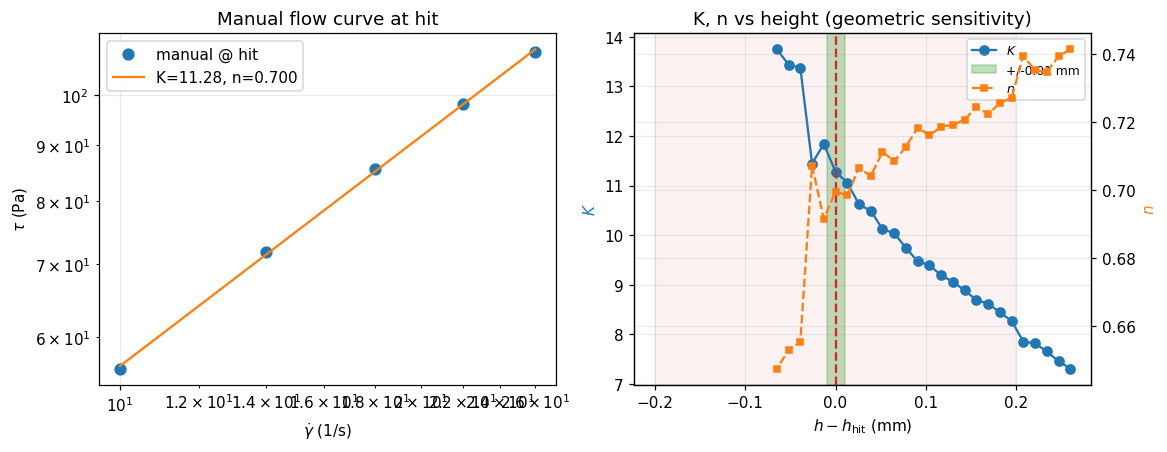

Geometric error budget (same fluid/fit; only gap changes):


,condition,h_rel_mm,K,n,dK_%,dn_%
0,hit (0),0.000,11.278,0.700,0.000,0.000
1,+/-0.01 mm deep,-0.010,11.711,0.693,3.833,-0.887
2,+/-0.01 mm shallow,0.010,11.111,0.699,-1.481,-0.123
3,+/-0.20 mm deep* [clipped],-0.065,13.750,0.647,21.917,-7.456
4,+/-0.20 mm shallow,0.200,8.109,0.732,-28.101,4.622


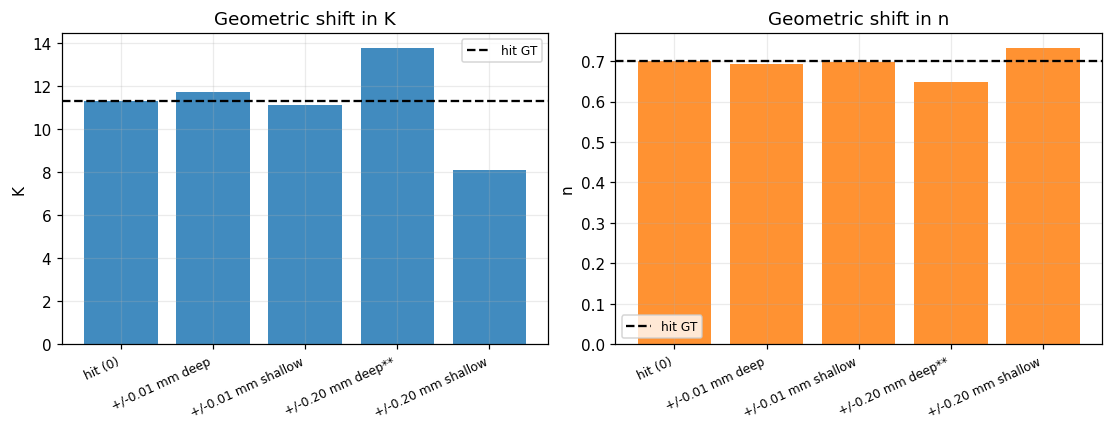


*** TARGET geometric floor (+/-10 um) ***
  max |dK| = 3.83%
  max |dn| = 0.89%
  => 10% K/n target is ABOVE this floor if hit is controlled to +/-0.01 mm.
  Today's ~0.2 mm-class hit jitter is far larger than that floor.


In [4]:
def eta_app_cp(K, n, g=G_REF):
    return float(K * (g ** (n - 1.0)) * 1000.0)

def pct_err(pred, truth):
    return float(100.0 * (pred - truth) / truth)

inc_rows = []
for inc, g in manual.groupby("Increment"):
    pl = fit_stress_powerlaw(g["gamma_dot_1_s"], g["tau_Pa"])
    inc_rows.append({
        "Increment": int(inc),
        "h_rel_mm": (int(inc) - HIT_INC) * MANUAL_INC_MM,
        "K": pl["K_stress"], "n": pl["n_stress"], "R2": pl["R2_stress"],
        "eta20_cP": eta_app_cp(pl["K_stress"], pl["n_stress"]),
        "mean_drag": float(g["drag"].mean()),
    })
inc_fit = pd.DataFrame(inc_rows).sort_values("h_rel_mm", ascending=False).reset_index(drop=True)
gt = inc_fit.loc[inc_fit["Increment"] == HIT_INC].iloc[0]
GT_K, GT_n, GT_ETA20 = float(gt["K"]), float(gt["n"]), float(gt["eta20_cP"])
print(f"Manual GT @ HIT_INC={HIT_INC}: K={GT_K:.3f}, n={GT_n:.3f}, eta20={GT_ETA20:.0f} cP, R2={gt['R2']:.5f}")

m_hit = manual[manual["Increment"] == HIT_INC]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), constrained_layout=True)
g_line = np.logspace(np.log10(m_hit["gamma_dot_1_s"].min()), np.log10(m_hit["gamma_dot_1_s"].max()), 50)
axes[0].loglog(m_hit["gamma_dot_1_s"], m_hit["tau_Pa"], "o", ms=7, label="manual @ hit")
axes[0].loglog(g_line, GT_K * g_line ** GT_n, "-", label=fr"K={GT_K:.2f}, n={GT_n:.3f}")
axes[0].set_xlabel(r"$\dot\gamma$ (1/s)"); axes[0].set_ylabel(r"$\tau$ (Pa)")
axes[0].set_title("Manual flow curve at hit"); axes[0].legend()

axes[1].plot(inc_fit["h_rel_mm"], inc_fit["K"], "o-", color="C0", label="$K$")
axn = axes[1].twinx()
axn.plot(inc_fit["h_rel_mm"], inc_fit["n"], "s--", color="C1", ms=4, label="$n$")
axes[1].axvline(0.0, color="C3", ls="--")
axes[1].axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.3, label="+/-0.01 mm")
axes[1].axvspan(-HIT_BUDGET_MM, HIT_BUDGET_MM, color="C3", alpha=0.06)
axes[1].set_xlabel(r"$h-h_{\mathrm{hit}}$ (mm)")
axes[1].set_ylabel(r"$K$", color="C0"); axn.set_ylabel(r"$n$", color="C1")
axes[1].set_title("K, n vs height (geometric sensitivity)")
h1,l1=axes[1].get_legend_handles_labels(); h2,l2=axn.get_legend_handles_labels()
axes[1].legend(h1+h2, l1+l2, fontsize=8, loc="best")
plt.show()

# Geometric error budget
def kn_at_h(h_mm):
    h = inc_fit["h_rel_mm"].to_numpy(float)
    K = inc_fit["K"].to_numpy(float)
    n = inc_fit["n"].to_numpy(float)
    o = np.argsort(h)
    return float(np.interp(h_mm, h[o], K[o])), float(np.interp(h_mm, h[o], n[o]))

h_min, h_max = float(inc_fit["h_rel_mm"].min()), float(inc_fit["h_rel_mm"].max())
geo_rows = []
for label, h in [
    ("hit (0)", 0.0),
    ("+/-0.01 mm deep", -HIT_FLOOR_MM),
    ("+/-0.01 mm shallow", +HIT_FLOOR_MM),
    ("+/-0.20 mm deep*", -HIT_BUDGET_MM),
    ("+/-0.20 mm shallow", +HIT_BUDGET_MM),
]:
    hc = float(np.clip(h, h_min, h_max))
    K, n = kn_at_h(hc)
    geo_rows.append({
        "condition": label + (" [clipped]" if abs(hc-h)>1e-9 else ""),
        "h_rel_mm": hc, "K": K, "n": n,
        "dK_%": pct_err(K, GT_K), "dn_%": pct_err(n, GT_n),
    })
geo = pd.DataFrame(geo_rows)
print("Geometric error budget (same fluid/fit; only gap changes):")
display(geo.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
labs = [r.replace(" [clipped]", "*") for r in geo["condition"]]
x = np.arange(len(labs))
axes[0].bar(x, geo["K"], color="C0", alpha=0.85)
axes[0].axhline(GT_K, color="k", ls="--", label="hit GT")
axes[0].set_xticks(x); axes[0].set_xticklabels(labs, rotation=25, ha="right", fontsize=8)
axes[0].set_ylabel("K"); axes[0].set_title("Geometric shift in K"); axes[0].legend(fontsize=8)
axes[1].bar(x, geo["n"], color="C1", alpha=0.85)
axes[1].axhline(GT_n, color="k", ls="--", label="hit GT")
axes[1].set_xticks(x); axes[1].set_xticklabels(labs, rotation=25, ha="right", fontsize=8)
axes[1].set_ylabel("n"); axes[1].set_title("Geometric shift in n"); axes[1].legend(fontsize=8)
plt.show()

Kd, nd = kn_at_h(max(-HIT_FLOOR_MM, h_min))
Ku, nu = kn_at_h(min(+HIT_FLOOR_MM, h_max))
print(f"\n*** TARGET geometric floor (+/-{HIT_FLOOR_MM*1e3:.0f} um) ***")
print(f"  max |dK| = {max(abs(pct_err(Kd,GT_K)), abs(pct_err(Ku,GT_K))):.2f}%")
print(f"  max |dn| = {max(abs(pct_err(nd,GT_n)), abs(pct_err(nu,GT_n))):.2f}%")
print("  => 10% K/n target is ABOVE this floor if hit is controlled to +/-0.01 mm.")
print("  Today's ~0.2 mm-class hit jitter is far larger than that floor.")


## 4. Production fits — one bar per cell

Live code today: `predict_cell_rheology` on **that cell only**. No other cells involved.


,experiment,full_name,hit_z,n,K,eta20_cP,err_n_%,err_K_%
0,c1,20261119_104557_cell1,-65.96,0.657,14.359,5133.781,-6.129,27.314
1,c2,20261119_104557_cell2,-65.80,0.630,17.720,5848.366,-9.946,57.112
2,c3,20261119_104557_cell3,-65.66,0.656,16.145,5762.599,-6.209,43.148
3,c7,20261119_104557_cell7,-65.94,0.640,17.283,5873.965,-8.547,53.241
4,c8,20261119_104557_cell8,-65.62,0.653,14.115,4983.877,-6.724,25.146
5,c7_d2,20261125_162622_cell7,-65.94,0.650,15.081,5289.994,-7.040,33.716


Production: n CV=1.5% mean|err|=7.4% | K CV=8.7% mean|err|=39.9%


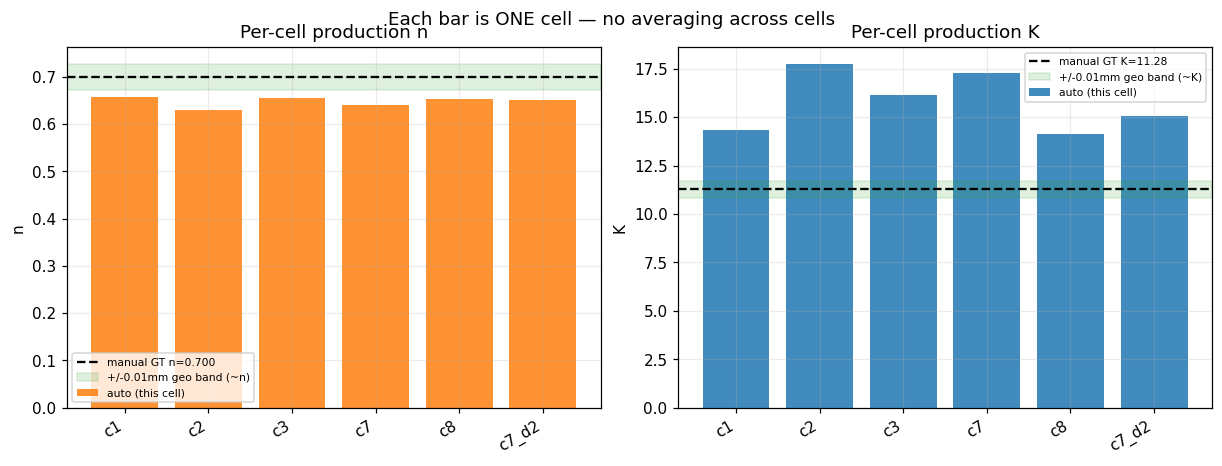

In [5]:
def points_from_exp(exp):
    d = exp["df"]; cell = int(exp["cell"]); hz = hit_z_from_flags(d)
    points = []
    for _, r in d.iterrows():
        rpm = float(r["RPM"]); torque = float(r["Torque_%"])
        drag = float(r["Rotational_Drag"]) if pd.notna(r["Rotational_Drag"]) else abs(torque)/rpm
        points.append({"cell_id": cell, "height": float(r["Z_Height_mm"]), "rpm": rpm,
                       "torque_percent": torque, "rotational_drag": drag})
    return points, hz, sorted(d["RPM"].unique().tolist())

prod_rows = []; per_rpm_store = {}
for exp in exps:
    points, hz, rpms = points_from_exp(exp)
    per_rpm, summary = predict_cell_rheology(exp["cell"], rpms, points, torque_floor_pct=0.0, hit_point_z=hz)
    per_rpm_store[exp["name"]] = per_rpm
    prod_rows.append({
        "experiment": exp["short"], "full_name": exp["name"], "hit_z": hz,
        "n": summary.get("n_stress"), "K": summary.get("K_stress"),
        "eta20_cP": eta_app_cp(summary["K_stress"], summary["n_stress"]) if summary.get("K_stress") else np.nan,
        "err_n_%": pct_err(summary.get("n_stress"), GT_n) if summary.get("n_stress") else np.nan,
        "err_K_%": pct_err(summary.get("K_stress"), GT_K) if summary.get("K_stress") else np.nan,
    })
prod = pd.DataFrame(prod_rows)
display(prod.round(3))

def cv_pct(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(100*s.std(ddof=0)/s.mean()) if len(s) and s.mean() else np.nan

print(f"Production: n CV={cv_pct(prod['n']):.1f}% mean|err|={prod['err_n_%'].abs().mean():.1f}% | "
      f"K CV={cv_pct(prod['K']):.1f}% mean|err|={prod['err_K_%'].abs().mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), constrained_layout=True)
x = np.arange(len(prod))
axes[0].bar(x, prod["n"], color="C1", alpha=0.85, label="auto (this cell)")
axes[0].axhline(GT_n, color="k", ls="--", label=f"manual GT n={GT_n:.3f}")
axes[0].axhspan(GT_n*(1-0.038), GT_n*(1+0.038), color="C2", alpha=0.15, label="+/-0.01mm geo band (~n)")
axes[0].set_xticks(x); axes[0].set_xticklabels(prod["experiment"], rotation=30, ha="right")
axes[0].set_ylabel("n"); axes[0].set_title("Per-cell production n"); axes[0].legend(fontsize=7)

axes[1].bar(x, prod["K"], color="C0", alpha=0.85, label="auto (this cell)")
axes[1].axhline(GT_K, color="k", ls="--", label=f"manual GT K={GT_K:.2f}")
axes[1].axhspan(GT_K*(1-0.04), GT_K*(1+0.04), color="C2", alpha=0.15, label="+/-0.01mm geo band (~K)")
axes[1].set_xticks(x); axes[1].set_xticklabels(prod["experiment"], rotation=30, ha="right")
axes[1].set_ylabel("K"); axes[1].set_title("Per-cell production K"); axes[1].legend(fontsize=7)
fig.suptitle("Each bar is ONE cell — no averaging across cells", y=1.02)
plt.show()


## 5. Live per-cell candidates (scrap multi-cell / shared-$n$)

These run on **one cell's gap×RPM sweep** during or right after collection:

| Candidate | Live change | Idea |
|---|---|---|
| **A. Fixed-offset stress** | After hit detect, evaluate $\tau$ at $h_{\mathrm{hit}}+\delta$ (e.g. 40–100 μm above contact), then log–OLS | Avoids contact-plateau / over-deep hit; protocol + fit |
| **B. Joint amplitude $n$ + stress $K$** | Keep per-RPM hyperbola $A(\mathrm{RPM})$; fit $n$ from $A\propto\dot\gamma^{n-1}$; get $K$ from $\tau/\dot\gamma^{n}$ on the same cell | Uses full gap curves for shape ($n$), stresses for scale ($K$) — still one cell |
| **C. Nonlinear LS on $\tau(\dot\gamma)$** | Replace log–OLS with NLS in $\tau$-space (optional accuracy weights) | Classical improvement; small effect here vs geometry |

**Removed (do not use for this platform goal):** shared-$n$ across cells, η-calibration from a bank, drag-matching that needs a manual library of gaps.

**Literature / practice anchors**
- Power-law $\tau=K\dot\gamma^{n}$ log or WLS fits on multi-speed data are standard for online / six-speed systems (field rheometry; weighted LS for heteroscedastic torque noise).
- Cone–plate **central gap / truncation** strongly affects torque for non-Newtonians — gap must be controlled or referenced ([Schüller & Salas-Bringas](http://nordicrheologysociety.org/Content/Transactions/2008/Posters/Sch%C3%BCller_Salas-Bringas.pdf); TruGap-type real-time gap control).
- Truncated-cone power-law torque integrals motivate fitting $(K,n)$ with an explicit gap offset $h_0$ rather than pretending $h=0$ is exact.


Per-cell LIVE methods only (each cell fitted alone; stats summarize 6 independent cells):


,method,n_mean,n_std,K_mean,K_std,abs_err_n,abs_err_K,n_cells
2,live: offset +100um logOLS,0.684,0.006,11.978,0.920,2.292,8.130,6
5,live: offset +60um logOLS,0.675,0.008,12.909,1.062,3.449,14.461,6
4,live: offset +40um logOLS,0.669,0.007,13.530,1.125,4.396,19.960,6
3,live: offset +20um logOLS,0.660,0.006,14.356,0.933,5.636,27.288,6
6,live: prod hyp+logOLS,0.648,0.011,15.784,1.512,7.432,39.946,6
0,live: NLS on tau_hit,0.643,0.011,16.010,1.435,8.116,41.954,6
1,live: joint amp-n + tau-K,0.492,0.049,24.411,3.151,29.698,116.439,6


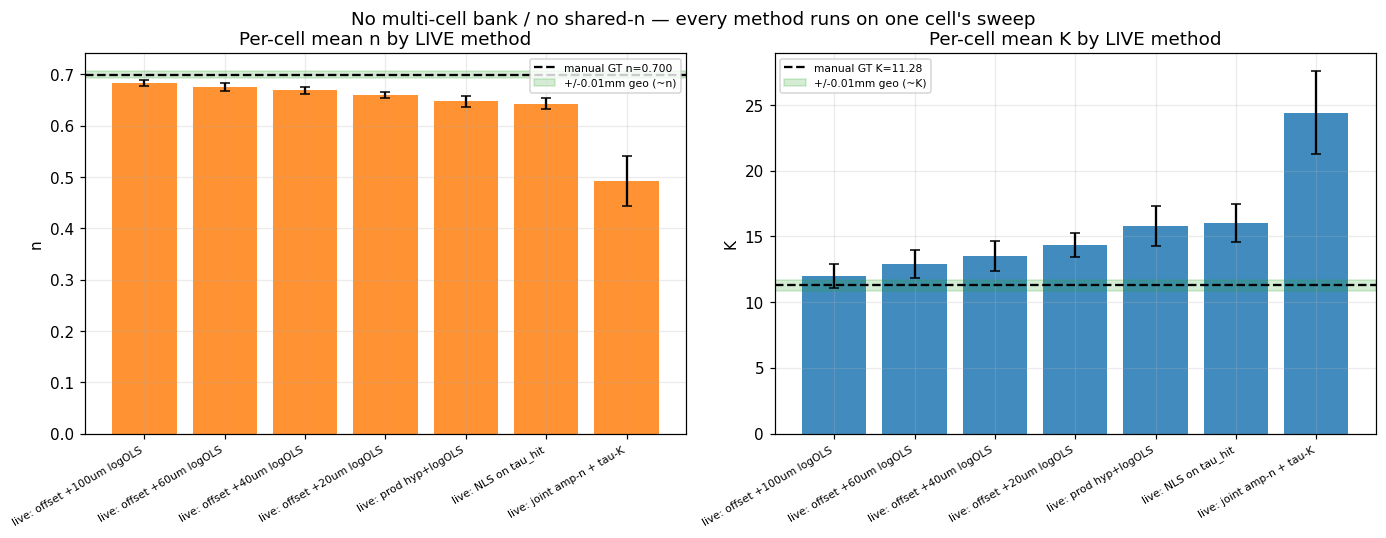

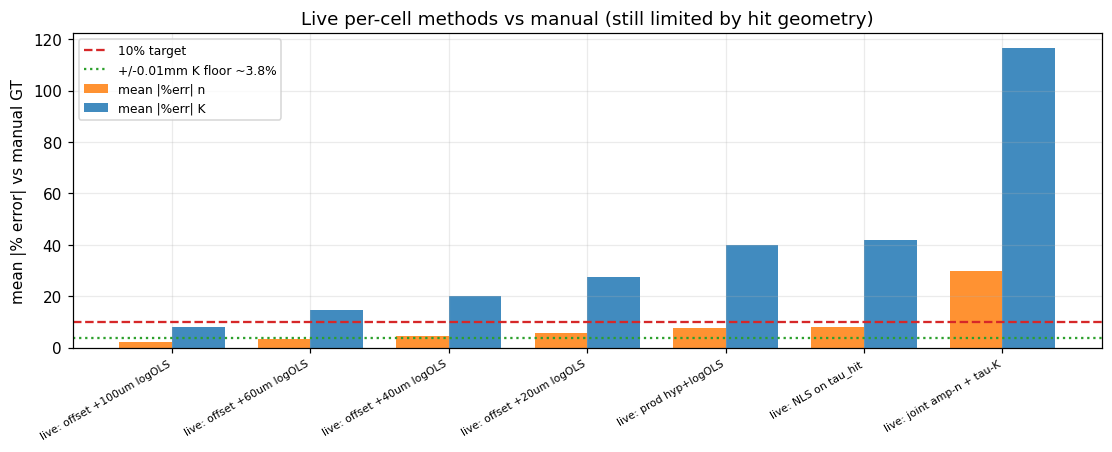


Reminder: improving the tau-gamma fitter without fixing hit depth cannot beat the geometric floor.
Offset methods change WHICH gap's stress is used (live protocol) — that is a per-cell collection/fit change.


In [6]:
# --- Live, per-cell estimators (no other cells required) ---

def tau_at_offset(exp, per_rpm, offset_mm):
    # Interpolate torque at h = hit + offset (above contact), convert to tau.
    points, hz, rpms = points_from_exp(exp)
    target = hz + offset_mm  # shallower than hit when offset>0 (machine Z larger)
    g, taus = [], []
    for rpm in rpms:
        if not per_rpm[rpm].get("success"):
            continue
        pts = filter_measurement_points(points, exp["cell"], float(rpm))
        if len(pts) < 2:
            continue
        zs = np.array([p["height"] for p in pts], float)
        ts = np.array([p["torque_percent"] for p in pts], float)
        o = np.argsort(zs)
        zs, ts = zs[o], ts[o]
        if target < zs.min() or target > zs.max():
            # clamp to available pre-hit window
            z_use = float(np.clip(target, zs.min(), zs.max()))
        else:
            z_use = target
        t_use = float(np.interp(z_use, zs, ts))
        if t_use <= 0:
            continue
        g.append(float(shear_rate(rpm)))
        taus.append(PCT_TO_PA * t_use)
    return np.asarray(g), np.asarray(taus)


def joint_amplitude_Kn(exp, per_rpm):
    # Per-RPM hyperbola amplitudes A_i, then A = A0 * gamma^(n-1); map to K via eta at gmin.
    points, hz, rpms = points_from_exp(exp)
    As, gs = [], []
    for rpm in rpms:
        fit = per_rpm[rpm]
        A = fit.get("A")
        if not fit.get("success") or A is None or not np.isfinite(A) or A <= 0:
            continue
        As.append(float(A)); gs.append(float(shear_rate(rpm)))
    if len(As) < 2:
        return {"K": np.nan, "n": np.nan}
    pl = fit_powerlaw(gs, As)
    n = float(pl["n"])
    # Viscosity from lowest-g amplitude using silicone linear map already in pathway;
    # here reconstruct K from hit stresses' power law on amplitude-implied ranking:
    # Use tau_hit from production but n from amplitude fit, K from mean tau/g^n
    taus, g2 = [], []
    for rpm, fit in per_rpm.items():
        if not fit.get("success"):
            continue
        tau = fit.get("tau_Pa_hit")
        if tau is None or not np.isfinite(tau) or tau <= 0:
            continue
        taus.append(float(tau)); g2.append(float(shear_rate(rpm)))
    g2, taus = np.asarray(g2), np.asarray(taus)
    K = float(np.exp(np.mean(np.log(taus) - n * np.log(g2))))
    return {"K": K, "n": n}


def nls_Kn(g, t):
    g = np.asarray(g, float); t = np.asarray(t, float)
    m = np.isfinite(g) & np.isfinite(t) & (g > 0) & (t > 0)
    g, t = g[m], t[m]
    if len(g) < 2:
        return {"K": np.nan, "n": np.nan}
    seed = fit_stress_powerlaw(g, t)
    def model(x, K, n):
        return K * np.power(x, n)
    popt, _ = curve_fit(model, g, t, p0=[seed["K_stress"], seed["n_stress"]],
                        bounds=([1e-6, 0.05], [1e3, 1.5]), maxfev=20000)
    return {"K": float(popt[0]), "n": float(popt[1])}


OFFSETS = [0.02, 0.04, 0.06, 0.10]  # mm above hit — live protocol choices
live_rows = []
for exp, prow in zip(exps, prod.itertuples(index=False)):
    # 1) production (baseline)
    live_rows.append({"experiment": exp["short"], "method": "live: prod hyp+logOLS",
                      "K": prow.K, "n": prow.n})
    # 2) NLS on production hit stresses
    g_hit, t_hit = [], []
    for rpm, fit in per_rpm_store[exp["name"]].items():
        if fit.get("success") and fit.get("tau_Pa_hit"):
            g_hit.append(float(shear_rate(rpm))); t_hit.append(float(fit["tau_Pa_hit"]))
    nls = nls_Kn(g_hit, t_hit)
    live_rows.append({"experiment": exp["short"], "method": "live: NLS on tau_hit",
                      "K": nls["K"], "n": nls["n"]})
    # 3) joint amplitude n + K from tau_hit magnitudes
    ja = joint_amplitude_Kn(exp, per_rpm_store[exp["name"]])
    live_rows.append({"experiment": exp["short"], "method": "live: joint amp-n + tau-K",
                      "K": ja["K"], "n": ja["n"]})
    # 4) fixed-offset stress (live protocol): evaluate tau at hit+delta
    for off in OFFSETS:
        g, t = tau_at_offset(exp, per_rpm_store[exp["name"]], off)
        if len(g) < 2:
            continue
        pl = fit_stress_powerlaw(g, t)
        live_rows.append({"experiment": exp["short"],
                          "method": f"live: offset +{off*1e3:.0f}um logOLS",
                          "K": pl["K_stress"], "n": pl["n_stress"]})

live = pd.DataFrame(live_rows)
live["err_K_%"] = live["K"].apply(lambda v: pct_err(v, GT_K) if np.isfinite(v) else np.nan)
live["err_n_%"] = live["n"].apply(lambda v: pct_err(v, GT_n) if np.isfinite(v) else np.nan)

summary = (
    live.groupby("method")
    .agg(n_mean=("n","mean"), n_std=("n","std"),
         K_mean=("K","mean"), K_std=("K","std"),
         abs_err_n=("err_n_%", lambda s: float(np.nanmean(np.abs(s)))),
         abs_err_K=("err_K_%", lambda s: float(np.nanmean(np.abs(s)))),
         n_cells=("experiment", "nunique"))
    .reset_index()
    .sort_values("abs_err_K")
)
print("Per-cell LIVE methods only (each cell fitted alone; stats summarize 6 independent cells):")
display(summary.round(3))

# Bar charts
order = summary["method"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
x = np.arange(len(summary))
axes[0].bar(x, summary["n_mean"], yerr=summary["n_std"].fillna(0), color="C1", alpha=0.85, capsize=3)
axes[0].axhline(GT_n, color="k", ls="--", label=f"manual GT n={GT_n:.3f}")
axes[0].axhspan(GT_n*0.991, GT_n*1.009, color="C2", alpha=0.2, label="+/-0.01mm geo (~n)")
axes[0].set_xticks(x); axes[0].set_xticklabels(summary["method"], rotation=30, ha="right", fontsize=7)
axes[0].set_ylabel("n"); axes[0].set_title("Per-cell mean n by LIVE method"); axes[0].legend(fontsize=7)

axes[1].bar(x, summary["K_mean"], yerr=summary["K_std"].fillna(0), color="C0", alpha=0.85, capsize=3)
axes[1].axhline(GT_K, color="k", ls="--", label=f"manual GT K={GT_K:.2f}")
axes[1].axhspan(GT_K*0.962, GT_K*1.038, color="C2", alpha=0.2, label="+/-0.01mm geo (~K)")
axes[1].set_xticks(x); axes[1].set_xticklabels(summary["method"], rotation=30, ha="right", fontsize=7)
axes[1].set_ylabel("K"); axes[1].set_title("Per-cell mean K by LIVE method"); axes[1].legend(fontsize=7)
fig.suptitle("No multi-cell bank / no shared-n — every method runs on one cell's sweep", y=1.03)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.0), constrained_layout=True)
w = 0.38
ax.bar(x - w/2, summary["abs_err_n"], width=w, color="C1", alpha=0.85, label="mean |%err| n")
ax.bar(x + w/2, summary["abs_err_K"], width=w, color="C0", alpha=0.85, label="mean |%err| K")
ax.axhline(10, color="C3", ls="--", label="10% target")
ax.axhline(3.8, color="C2", ls=":", label="+/-0.01mm K floor ~3.8%")
ax.set_xticks(x); ax.set_xticklabels(summary["method"], rotation=30, ha="right", fontsize=7)
ax.set_ylabel("mean |% error| vs manual GT")
ax.set_title("Live per-cell methods vs manual (still limited by hit geometry)")
ax.legend(fontsize=8)
plt.show()

# Per-cell view for best offset method vs production
best_off = summary.loc[summary["method"].str.contains("offset"), "abs_err_K"].idxmin() if summary["method"].str.contains("offset").any() else None
print("\nReminder: improving the tau-gamma fitter without fixing hit depth cannot beat the geometric floor.")
print("Offset methods change WHICH gap's stress is used (live protocol) — that is a per-cell collection/fit change.")


## 6. What to implement for live collection

**Honest constraint.** No curve-fit change beats a bad hit. With **$\pm 0.01\,\mathrm{mm}$** hit, geometric $|{\Delta}K|\sim 4\%$, $|{\Delta}n|\sim 1\%$ on this fluid — inside a 10% target. Production $K$ errors of tens of percent imply effective geometry/hit error **much larger than 0.01 mm** (or an absolute torque scale offset).

**Recommended live stack (per cell)**
1. **Detect hit** as now (drag feedback).
2. **Measure / interpolate at a fixed offset** $\delta$ above hit (Candidate A) — do not use extrapolated contact stress.
3. **Fit $(K,n)$** with log–OLS or NLS on that cell's multi-RPM stresses; optionally take $n$ from joint amplitudes (Candidate B) if hyperbola $R^2$ is high across RPMs.
4. **Report** $n$, $K$, and $\eta_{\mathrm{app}}(\dot\gamma_{\mathrm{ref}})$ for that cell, plus the $\delta$ used and hit $Z$.

**Controller hook points:** after `extract_hitpoint` / vote-hit in `run/controller.py`, add a short multi-RPM dwell (or interpolate existing sweep) at `hit_z + delta_mm` before characterization in `live_adapter` / `characterization.py`.

## 7. Conclusions
1. Manual GT (HIT_INC=1): $K\approx 11.28$, $n\approx 0.700$.
2. Geometric floor at $\pm 0.01\,\mathrm{mm}$: ~4% $K$, ~1% $n$ — 10% is realistic **per cell** if hit meets that.
3. Multi-cell shared-$n$ / bank calibration rejected for platform goals.
4. Pursue **live fixed-offset stress** + optional **joint amplitude $n$** on each cell's own sweep.

### References
1. Chhabra & Richardson — Ostwald–de Waele; state the $\dot\gamma$ window with $K,n$.
2. Schüller & Salas-Bringas (NRS 2008) — cone–plate central gap sensitivity.
3. TruGap / real-time gap control literature — gap error → viscosity/$K$ error.
4. Online multi-speed rheometry + weighted LS (drilling-fluid six-speed practice) — per-sample $(K,n)$ without a bank.
5. Project hyperbolic Newtonian path — `MANUSCRIPT_rheology.md` (geometry-first lesson carries over).
